<a href="https://colab.research.google.com/github/kabeer-necrox/1stjan/blob/master/EDA_portfilo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("this is my EDA portifilo project")

this is my EDA portifilo project


In [2]:
# Step 0: Import libraries and load ONLY the columns relevant to pricing & property features
import re
from difflib import get_close_matches
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

file_path = "/content/Scraped_Zameen_Data.xlsx - Sheet1.csv"

# List of important columns to load from the CSV
selected_cols = [
    "Title",
    "URL",
    "City",
    "Location",
    "Price",
    "Purpose",
    "Type",
    "Area",
    "Bedrooms",
    "Bathrooms",
    "Kitchens",
    "Parking Spaces",
    "Description"
]

# Load only those columns into pandas
df = pd.read_csv(file_path, usecols=selected_cols)
print("Loaded shape (rows, columns):", df.shape)
df.head(3)

Loaded shape (rows, columns): (18255, 13)


,Title,URL,City,Type,Area,Price,Purpose,Location,Description,Parking Spaces,Bedrooms,Bathrooms,Kitchens
0,Hmr Waterfront 2 Bed Room Premium Apartment On...,https://www.zameen.com/Property/dha_phase_8_hm...,Karachi,Flat,128 Sq. Yd.,PKR\n4.75 Crore,For Sale,"DHA Defence, Karachi, Sindh",SAIMA MARINA RESIDENCE HMR WATERFRONT\nINVESTO...,NaN,2,2,NaN
1,Chance Deal! Luxury 2 Bedroom Seafront Apartme...,https://www.zameen.com/Property/dha_defence_dh...,Karachi,Flat,161 Sq. Yd.,PKR\n6.25 Crore,For Sale,"DHA Defence, Karachi, Sindh",Live the Seafront Dream at H&S Residence \n2 B...,NaN,2,3,1.0
2,Luxury 1 Bed At H& S Residence By Japanese Arc...,https://www.zameen.com/Property/dha_phase_8_hm...,Karachi,Flat,111 Sq. Yd.,PKR\n3.45 Crore,For Sale,"DHA Defence, Karachi, Sindh",Live the Seafront Dream at H&S Residence \n1 B...,NaN,1,2,NaN


In [3]:
# --- Section 2: Data Understanding & Preprocessing ---

# 1. Inspect column data types and non-null counts
print("--- Basic Dataset Info ---")
df.info()

# 2. Remove duplicate rows
rows_before = len(df)

# Drop exact duplicate rows first
df = df.drop_duplicates()

# Drop duplicate listing URLs (each URL is one unique ad on Zameen.com)
df = df.drop_duplicates(subset=["URL"], keep="first")

# Drop reposted ads with identical property details
dupe_cols = ["Title", "City", "Location", "Price", "Area", "Type"]
df = df.drop_duplicates(subset=dupe_cols, keep="first").reset_index(drop=True)

rows_after = len(df)
print(f"\nRows before: {rows_before}")
print(f"Rows after removing duplicates: {rows_after}")
print(f"Duplicates removed: {rows_before - rows_after}")

--- Basic Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18255 entries, 0 to 18254
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Title           18239 non-null  object 
 1   URL             18255 non-null  object 
 2   City            18255 non-null  object 
 3   Type            18239 non-null  object 
 4   Area            18239 non-null  object 
 5   Price           18239 non-null  object 
 6   Purpose         18239 non-null  object 
 7   Location        18239 non-null  object 
 8   Description     14893 non-null  object 
 9   Parking Spaces  9656 non-null   float64
 10  Bedrooms        18239 non-null  object 
 11  Bathrooms       18239 non-null  object 
 12  Kitchens        13256 non-null  float64
dtypes: float64(2), object(11)
memory usage: 1.8+ MB

Rows before: 18255
Rows after removing duplicates: 17763
Duplicates removed: 492


In [4]:
# --- Section 3: Missing Values Treatment ---

# 1. Identify missing values in the entire dataset and per column
total_missing = df.isna().sum().sum()
print(f"Total missing cells in dataset: {total_missing:,}")

missing_table = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
})
display(missing_table[missing_table["Missing_Count"] > 0].sort_values("Missing_Percent", ascending=False))

# 2. Convert Bedrooms & Bathrooms to numeric first (bad text becomes NaN)
for col in ["Bedrooms", "Bathrooms", "Kitchens", "Parking Spaces"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 3. Impute categorical columns with Mode (most frequent category)
for col in ["City", "Location", "Type", "Purpose"]:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# 4. Impute Kitchens & Parking Spaces with 0 (unlisted optional features = 0)
df["Kitchens"] = df["Kitchens"].fillna(0)
df["Parking Spaces"] = df["Parking Spaces"].fillna(0)

# 5. Impute Bedrooms & Bathrooms using Median grouped by Property Type
# (e.g., Plots get 0, Flats/Houses get their typical median count)
for col in ["Bedrooms", "Bathrooms"]:
    type_median = df.groupby("Type")[col].transform("median")
    df[col] = df[col].fillna(type_median).fillna(df[col].median())

# 6. Drop rows where core target/size (Price, Area, or Description) is missing
df["Description"] = df["Description"].fillna("No description")
df = df.dropna(subset=["Price", "Area"]).reset_index(drop=True)

print("\nRemaining missing values after treatment:")
print(df.isna().sum())

Total missing cells in dataset: 16,497


,Missing_Count,Missing_Percent
Parking Spaces,8308,46.77
Kitchens,4850,27.30
Description,3275,18.44
Area,8,0.05
Type,8,0.05
Title,8,0.05
Price,8,0.05
Location,8,0.05
Purpose,8,0.05
Bedrooms,8,0.05



Remaining missing values after treatment:
Title             0
URL               0
City              0
Type              0
Area              0
Price             0
Purpose           0
Location          0
Description       0
Parking Spaces    0
Bedrooms          0
Bathrooms         0
Kitchens          0
dtype: int64


In [5]:
# --- Section 4: Data Cleaning & Consistency ---

# 1. Standardize City names using difflib fuzzy matching
pakistani_cities = [
    "Karachi", "Lahore", "Islamabad", "Rawalpindi", "Faisalabad",
    "Multan", "Peshawar", "Quetta", "Sialkot", "Gujranwala",
    "Bahawalpur", "Abbottabad", "Hyderabad", "Gwadar", "Murree", "Sargodha"
]

def clean_city_fuzzy(city_name):
    if pd.isna(city_name):
        return "Unknown"
    # Clean whitespace and capitalize properly
    cleaned = str(city_name).split(",")[0].strip().title()
    if cleaned in pakistani_cities:
        return cleaned
    # Find closest matching city name (cutoff=0.75 avoids false matches)
    matches = get_close_matches(cleaned, pakistani_cities, n=1, cutoff=0.75)
    return matches[0] if matches else cleaned

df["City_Clean"] = df["City"].apply(clean_city_fuzzy)
print("Unique standardized cities:", df["City_Clean"].value_counts().head(10).to_dict())

# 2. Clean Price column -> numeric PKR and Crore
def parse_price_to_pkr(price_str):
    if pd.isna(price_str):
        return np.nan
    text = str(price_str).lower().replace(",", "").replace("pkr", "").strip()
    match = re.search(r"(\d+(?:\.\d+)?)", text)
    if not match:
        return np.nan
    value = float(match.group(1))
    if "arab" in text:
        return value * 1_000_000_000
    elif "crore" in text:
        return value * 10_000_000
    elif "lakh" in text:
        return value * 100_000
    elif "thousand" in text or re.search(r"\bk\b", text):
        return value * 1_000
    return value

df["Price_PKR"] = df["Price"].apply(parse_price_to_pkr)
df["Price_Crore"] = df["Price_PKR"] / 10_000_000

# 3. Convert Area units (Marla / Kanal / Sq. Yd. / Sq. Ft.) -> uniform Sq. Ft.
unit_multipliers = {
    "sq. ft.": 1.0,
    "sq.ft.": 1.0,
    "sqft": 1.0,
    "sq. yd.": 9.0,
    "sq.yd.": 9.0,
    "sq yd": 9.0,
    "marla": 272.25,
    "kanal": 5445.0,
}

def convert_area_to_sqft(area_str):
    if pd.isna(area_str):
        return np.nan
    text = str(area_str).lower().replace(",", "").strip()
    match = re.search(r"(\d+(?:\.\d+)?)", text)
    if not match:
        return np.nan
    number = float(match.group(1))
    for unit, multiplier in unit_multipliers.items():
        if unit in text:
            return number * multiplier
    return np.nan

df["Area_SqFt"] = df["Area"].apply(convert_area_to_sqft)

# Check if any Area strings failed to convert
unconverted = df[df["Area_SqFt"].isna()]["Area"].unique()
print("Unconverted Area strings:", unconverted)

# 4. Standardize Purpose column ("For Sale" vs "For Rent")
def clean_purpose(purpose_str):
    text = str(purpose_str).strip().lower()
    if "rent" in text or "lease" in text:
        return "For Rent"
    elif "sale" in text or "buy" in text:
        return "For Sale"
    return text.title()

df["Purpose_Clean"] = df["Purpose"].apply(clean_purpose)
print("\nPurpose counts:\n", df["Purpose_Clean"].value_counts())

# Filter to 'For Sale' listings so sale prices aren't mixed with monthly rents
df_sale = df[df["Purpose_Clean"] == "For Sale"].dropna(subset=["Price_PKR", "Area_SqFt"]).copy()

# 5. Detect and remove nonsensical price/area outliers
# Domain rule: Sale property in Pakistan < 5 Lakh (500,000 PKR) or < 100 Sq. Ft. is a typo/token
# Upper cap: remove extreme scraping typos above 99.5th percentile
upper_price_cap = df_sale["Price_PKR"].quantile(0.995)
upper_area_cap = df_sale["Area_SqFt"].quantile(0.995)

before_outliers = len(df_sale)
df_sale = df_sale[
    (df_sale["Price_PKR"] >= 500_000) &
    (df_sale["Price_PKR"] <= upper_price_cap) &
    (df_sale["Area_SqFt"] >= 100) &
    (df_sale["Area_SqFt"] <= upper_area_cap)
].reset_index(drop=True)

print(f"\nFor Sale rows before outlier filtering: {before_outliers}")
print(f"For Sale rows after outlier filtering:  {len(df_sale)}")
print(f"Outliers removed:                       {before_outliers - len(df_sale)}")

display(df_sale[["City_Clean", "Type", "Area", "Area_SqFt", "Price", "Price_Crore"]].head(5))

Unique standardized cities: {'Karachi': 2471, 'Islamabad': 2465, 'Rawalpindi': 2393, 'Lahore': 2371, 'Multan': 1578, 'Gujranwala': 1546, 'Faisalabad': 1490, 'Peshawar': 1130, 'Sialkot': 480, 'Hyderabad': 328}
Unconverted Area strings: []

Purpose counts:
 Purpose_Clean
For Sale    10793
For          6962
Name: count, dtype: int64

For Sale rows before outlier filtering: 10793
For Sale rows after outlier filtering:  10692
Outliers removed:                       101


,City_Clean,Type,Area,Area_SqFt,Price,Price_Crore
0,Karachi,Flat,128 Sq. Yd.,1152.0,PKR\n4.75 Crore,4.75
1,Karachi,Flat,161 Sq. Yd.,1449.0,PKR\n6.25 Crore,6.25
2,Karachi,Flat,111 Sq. Yd.,999.0,PKR\n3.45 Crore,3.45
3,Karachi,Flat,106 Sq. Yd.,954.0,PKR\n2.98 Crore,2.98
4,Karachi,Flat,156 Sq. Yd.,1404.0,PKR\n4.65 Crore,4.65


In [6]:
# --- Section 5: Feature Engineering ---

# 1. Price per square foot (key valuation metric)
df_sale["Price_per_SqFt"] = df_sale["Price_PKR"] / df_sale["Area_SqFt"]

# 2. Group area into standard Pakistani property size tiers
def get_size_tier(sqft):
    if sqft < 1361.25:       # < 5 Marla
        return "Under 5 Marla"
    elif sqft < 2722.5:      # 5 to < 10 Marla
        return "5 - 10 Marla"
    elif sqft < 5445.0:      # 10 Marla to < 1 Kanal
        return "10 Marla - 1 Kanal"
    else:                    # >= 1 Kanal
        return "1 Kanal+"

df_sale["Size_Tier"] = df_sale["Area_SqFt"].apply(get_size_tier)

# 3. Total rooms/spaces count
df_sale["Total_Rooms"] = (
    df_sale["Bedrooms"] +
    df_sale["Bathrooms"] +
    df_sale["Kitchens"] +
    df_sale["Parking Spaces"]
)

# 4. Extract useful signals from Title + Description text
combined_text = (df_sale["Title"].fillna("") + " " + df_sale["Description"].fillna("")).str.lower()

df_sale["Is_Corner"] = combined_text.str.contains(r"\bcorner\b", regex=True).astype(int)
df_sale["Is_West_Open"] = combined_text.str.contains(r"west\s*open", regex=True).astype(int)
df_sale["Is_Brand_New"] = combined_text.str.contains(r"brand\s*new", regex=True).astype(int)
df_sale["Is_Instalment"] = combined_text.str.contains(r"instal+ment|installment", regex=True).astype(int)

# Preview newly engineered features
display(df_sale[[
    "City_Clean", "Type", "Price_Crore", "Area_SqFt", "Price_per_SqFt",
    "Size_Tier", "Total_Rooms", "Is_Corner", "Is_Instalment"
]].head(8))

,City_Clean,Type,Price_Crore,Area_SqFt,Price_per_SqFt,Size_Tier,Total_Rooms,Is_Corner,Is_Instalment
0,Karachi,Flat,4.75,1152.0,41232.638889,Under 5 Marla,4.0,0,1
1,Karachi,Flat,6.25,1449.0,43133.195307,5 - 10 Marla,6.0,0,1
2,Karachi,Flat,3.45,999.0,34534.534535,Under 5 Marla,3.0,0,1
3,Karachi,Flat,2.98,954.0,31236.897275,Under 5 Marla,8.0,0,1
4,Karachi,Flat,4.65,1404.0,33119.658120,5 - 10 Marla,4.0,1,1
5,Karachi,Flat,2.60,1953.0,13312.852023,5 - 10 Marla,9.0,1,0
6,Karachi,House,6.75,2160.0,31250.000000,5 - 10 Marla,24.0,0,0
7,Karachi,House,1.68,1800.0,9333.333333,5 - 10 Marla,6.0,0,0


In [7]:
# Quick sanity check on engineered numeric features
display(df_sale[["Price_Crore", "Area_SqFt", "Price_per_SqFt", "Total_Rooms"]].describe().round(2))

# Inspect any rows with unusually high Total_Rooms (e.g., > 15)
display(df_sale[df_sale["Total_Rooms"] > 15][["City_Clean", "Type", "Bedrooms", "Bathrooms", "Kitchens", "Parking Spaces", "Total_Rooms"]].head(5))

,Price_Crore,Area_SqFt,Price_per_SqFt,Total_Rooms
count,10692.00,10692.00,10692.00,10692.00
mean,4.60,2635.24,16159.99,13.74
std,6.18,2241.69,10102.39,36.19
min,0.16,108.90,73.46,2.00
25%,1.70,1361.25,11352.37,9.00
50%,2.80,1905.75,13957.76,12.00
75%,4.80,2722.50,17840.75,15.00
max,63.00,21780.00,301587.30,2028.00


,City_Clean,Type,Bedrooms,Bathrooms,Kitchens,Parking Spaces,Total_Rooms
6,Karachi,House,9.0,6.0,3.0,6.0,24.0
8,Karachi,House,6.0,6.0,2.0,2.0,16.0
45,Karachi,House,5.0,6.0,2.0,4.0,17.0
46,Karachi,House,6.0,6.0,2.0,4.0,18.0
47,Karachi,House,6.0,6.0,2.0,4.0,18.0


In [8]:
# --- Summary Numbers for Section 7 & 8 Report ---
print("1. Overall Sale Dataset Summary:")
display(df_sale[["Price_Crore", "Area_SqFt", "Price_per_SqFt", "Bedrooms", "Bathrooms"]].median().round(2))

print("\n2. Top 6 Cities by Listing Count (Median Price & Price/SqFt):")
top6_cities = df_sale["City_Clean"].value_counts().head(6).index
display(
    df_sale[df_sale["City_Clean"].isin(top6_cities)]
    .groupby("City_Clean")
    .agg(
        Listings=("Price_PKR", "count"),
        Median_Price_Crore=("Price_Crore", "median"),
        Median_Area_SqFt=("Area_SqFt", "median"),
        Median_Price_SqFt=("Price_per_SqFt", "median")
    )
    .round(2)
    .sort_values("Median_Price_SqFt", ascending=False)
)

print("\n3. Property Type Comparison:")
display(
    df_sale.groupby("Type")
    .agg(
        Listings=("Price_PKR", "count"),
        Median_Price_Crore=("Price_Crore", "median"),
        Median_Price_SqFt=("Price_per_SqFt", "median")
    )
    .round(2)
    .sort_values("Listings", ascending=False)
)

print("\n4. Keyword Premium Check (Median Price/SqFt when Flag = 1 vs 0):")
for flag in ["Is_Corner", "Is_West_Open", "Is_Brand_New", "Is_Instalment"]:
    medians = df_sale.groupby(flag)["Price_per_SqFt"].median().round(0).to_dict()
    print(f"{flag:15s} -> No (0): {medians.get(0, 'N/A')} PKR/sqft | Yes (1): {medians.get(1, 'N/A')} PKR/sqft")

1. Overall Sale Dataset Summary:


,0
Price_Crore,2.80
Area_SqFt,1905.75
Price_per_SqFt,13957.76
Bedrooms,5.00
Bathrooms,5.00



2. Top 6 Cities by Listing Count (Median Price & Price/SqFt):


,Listings,Median_Price_Crore,Median_Area_SqFt,Median_Price_SqFt
City_Clean,,,,
Karachi,1235,3.45,1800.00,18981.48
Islamabad,1171,4.50,2722.50,18218.55
Lahore,1165,3.15,2178.00,14618.92
Faisalabad,1139,2.40,1579.05,14325.07
Rawalpindi,1166,3.68,2722.50,14325.07
Multan,1169,2.10,1905.75,11019.28



3. Property Type Comparison:


,Listings,Median_Price_Crore,Median_Price_SqFt
Type,,,
House,9332,2.95,14233.24
Flat,1244,1.68,12954.28
Upper Portion,52,2.70,13495.37
Farm House,35,3.70,2846.65
Penthouse,13,3.20,8457.78
Lower Portion,11,2.80,14583.33
Room,5,0.32,8395.64



4. Keyword Premium Check (Median Price/SqFt when Flag = 1 vs 0):
Is_Corner       -> No (0): 13958.0 PKR/sqft | Yes (1): 14325.0 PKR/sqft
Is_West_Open    -> No (0): 13958.0 PKR/sqft | Yes (1): 16667.0 PKR/sqft
Is_Brand_New    -> No (0): 13774.0 PKR/sqft | Yes (1): 15243.0 PKR/sqft
Is_Instalment   -> No (0): 14065.0 PKR/sqft | Yes (1): 12949.0 PKR/sqft


/tmp/ipykernel_973/1102990146.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_sale[df_sale["Type"].isin(top_types)], y="Type", order=top_types, palette="viridis", ax=axes[1, 0])
/tmp/ipykernel_973/1102990146.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_sale[df_sale["Location"].isin(top_locs)], y="Location", order=top_locs, palette="magma", ax=axes[1, 1])


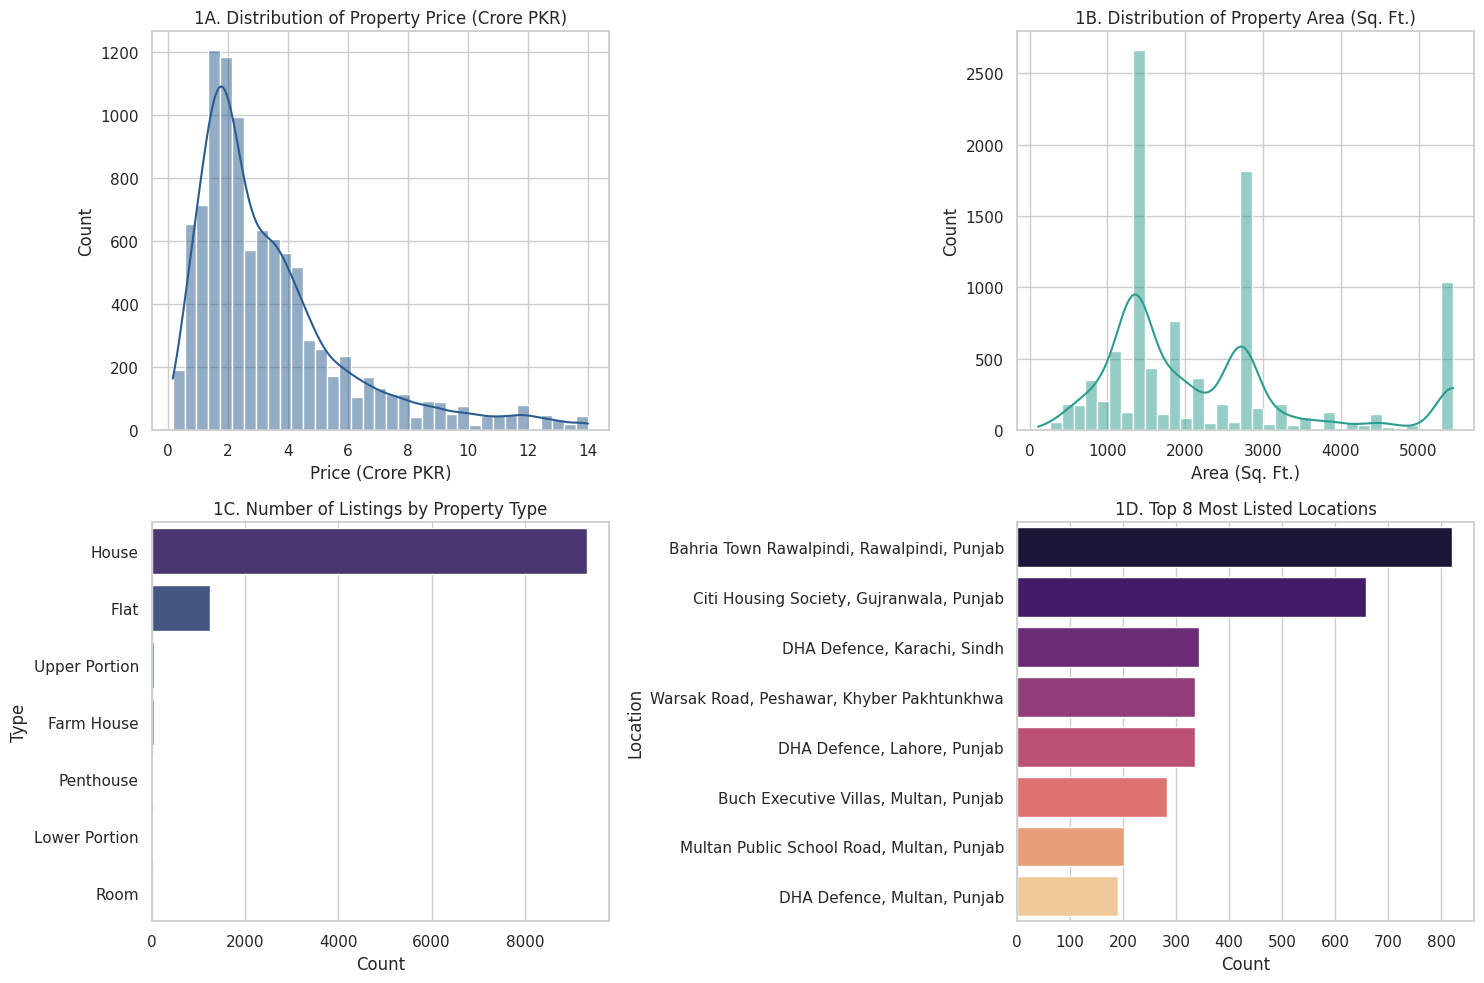

In [9]:
# --- Chart 1: Histograms (Price & Area) and Countplots (Type & Top Locations) ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Histogram of Price (capped at 95th percentile so luxury mansions don't squash the bars)
p95_price = df_sale["Price_Crore"].quantile(0.95)
sns.histplot(df_sale[df_sale["Price_Crore"] <= p95_price]["Price_Crore"], bins=35, kde=True, color="#2b5c8f", ax=axes[0, 0])
axes[0, 0].set_title("1A. Distribution of Property Price (Crore PKR)")
axes[0, 0].set_xlabel("Price (Crore PKR)")

# 2. Histogram of Area (capped at 95th percentile)
p95_area = df_sale["Area_SqFt"].quantile(0.95)
sns.histplot(df_sale[df_sale["Area_SqFt"] <= p95_area]["Area_SqFt"], bins=35, kde=True, color="#2a9d8f", ax=axes[0, 1])
axes[0, 1].set_title("1B. Distribution of Property Area (Sq. Ft.)")
axes[0, 1].set_xlabel("Area (Sq. Ft.)")

# 3. Countplot of Property Type
top_types = df_sale["Type"].value_counts().head(7).index
sns.countplot(data=df_sale[df_sale["Type"].isin(top_types)], y="Type", order=top_types, palette="viridis", ax=axes[1, 0])
axes[1, 0].set_title("1C. Number of Listings by Property Type")
axes[1, 0].set_xlabel("Count")

# 4. Countplot of Top 8 Locations
top_locs = df_sale["Location"].value_counts().head(8).index
sns.countplot(data=df_sale[df_sale["Location"].isin(top_locs)], y="Location", order=top_locs, palette="magma", ax=axes[1, 1])
axes[1, 1].set_title("1D. Top 8 Most Listed Locations")
axes[1, 1].set_xlabel("Count")

plt.tight_layout()
plt.show()

In [10]:
# --- Chart 2: Interactive Barplot of Aggregated City Metrics ---
top_cities = df_sale["City_Clean"].value_counts().head(8).index

city_agg = (
    df_sale[df_sale["City_Clean"].isin(top_cities)]
    .groupby("City_Clean", as_index=False)
    .agg(
        Median_Price_Crore=("Price_Crore", "median"),
        Median_Price_SqFt=("Price_per_SqFt", "median"),
        Total_Listings=("Price_PKR", "count")
    )
    .sort_values("Median_Price_SqFt", ascending=False)
)

fig = px.bar(
    city_agg,
    x="City_Clean",
    y="Median_Price_SqFt",
    color="Median_Price_Crore",
    text=city_agg["Median_Price_SqFt"].round(0),
    hover_data=["Total_Listings", "Median_Price_Crore"],
    title="2. Median Price per Sq. Ft. (PKR) by City (Colored by Median Price in Crore)",
    labels={"City_Clean": "City", "Median_Price_SqFt": "Median Price / Sq. Ft. (PKR)"}
)
fig.update_traces(textposition="outside")
fig.show()

/tmp/ipykernel_973/4172162510.py:5: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_973/4172162510.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_973/4172162510.py:26: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




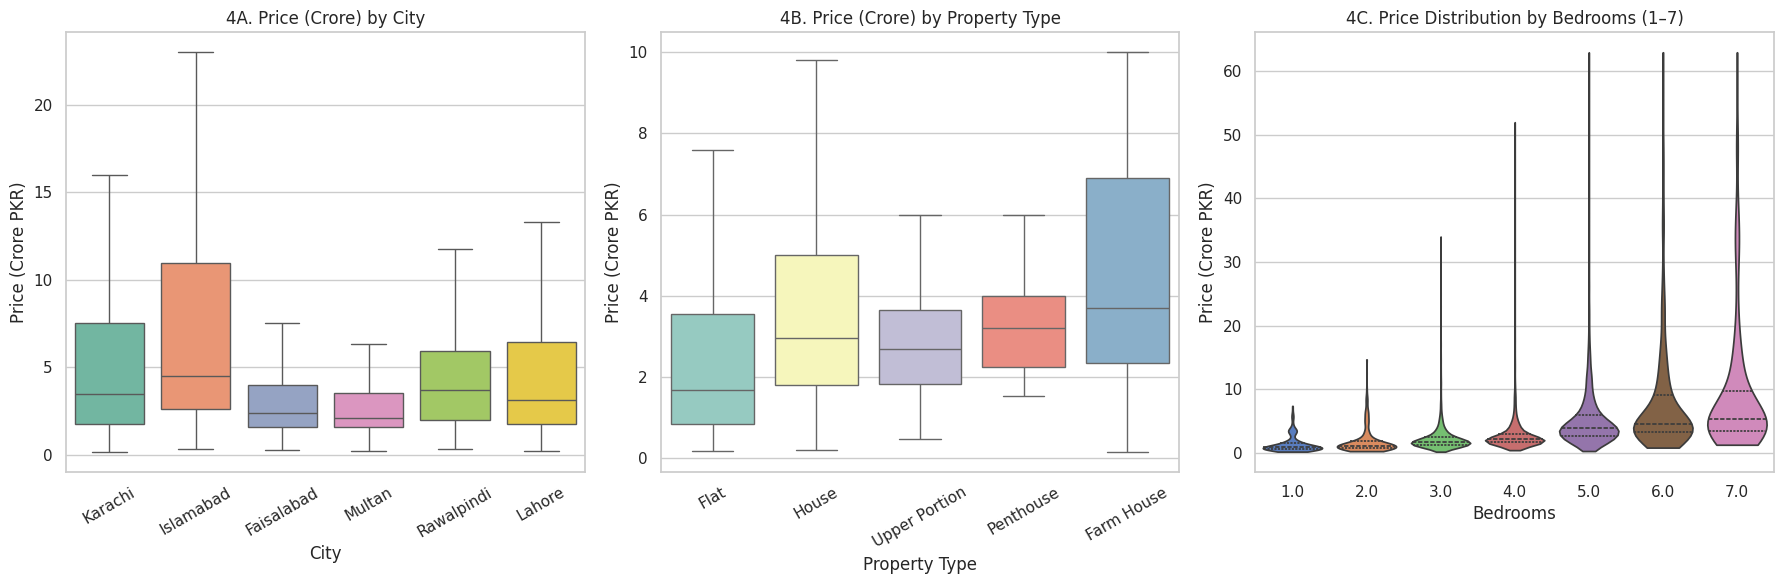

In [11]:
# --- Chart 4: Box Plots & Violin Plot ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 4A. Boxplot: Price by Top 6 Cities
sns.boxplot(
    data=df_sale[df_sale["City_Clean"].isin(top_cities[:6])],
    x="City_Clean", y="Price_Crore", showfliers=False, palette="Set2", ax=axes[0]
)
axes[0].set_title("4A. Price (Crore) by City")
axes[0].set_xlabel("City")
axes[0].set_ylabel("Price (Crore PKR)")
axes[0].tick_params(axis="x", rotation=30)

# 4B. Boxplot: Price by Top 5 Property Types
sns.boxplot(
    data=df_sale[df_sale["Type"].isin(top_types[:5])],
    x="Type", y="Price_Crore", showfliers=False, palette="Set3", ax=axes[1]
)
axes[1].set_title("4B. Price (Crore) by Property Type")
axes[1].set_xlabel("Property Type")
axes[1].set_ylabel("Price (Crore PKR)")
axes[1].tick_params(axis="x", rotation=30)

# 4C. Violin Plot: Price by Bedroom Count (1 to 7)
bed_subset = df_sale[df_sale["Bedrooms"].between(1, 7)]
sns.violinplot(
    data=bed_subset,
    x="Bedrooms", y="Price_Crore", inner="quartile", cut=0, palette="muted", ax=axes[2]
)
axes[2].set_title("4C. Price Distribution by Bedrooms (1–7)")
axes[2].set_xlabel("Bedrooms")
axes[2].set_ylabel("Price (Crore PKR)")

plt.tight_layout()
plt.show()